# Laboratorio 2



Jorge Caro 202020807

David Beltrán Gómez 202626681

[Video Lab 2](https://uniandes-my.sharepoint.com/:v:/g/personal/de_beltran_uniandes_edu_co/IQBH2NItMuUCQKlS5a93UBRCAfY2A3fmM_6RV23Caxl3uFE?nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJPbmVEcml2ZUZvckJ1c2luZXNzIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXciLCJyZWZlcnJhbFZpZXciOiJNeUZpbGVzTGlua0NvcHkifX0&e=MVp0mC)




## 1. Configuración inicial
Importando libreraias necesarias para el Laboratorio

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, PolynomialFeatures, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.utils import resample

In [40]:
uploaded = files.upload()
# Lee el archivo subido en un DataFrame de pandas
datos = pd.read_csv("Datos Lab 1.csv")
# Muestra la dimensión del dataset: (número de filas, número de columnas)
datos.shape

Saving Datos Lab 1.csv to Datos Lab 1 (1).csv


(2576, 27)

## 2. Preparación de los datos

Reutilizamos la función de limpieza del Laboratorio 1. Esa función normaliza las categorías y los meses, corrige las escalas de humedad y presión, intercambia los mínimos y máximos invertidos, elimina el centinela -9999 y codifica de forma cíclica el mes y la dirección del viento. Aplicamos esa limpieza, quitamos duplicados exactos y las filas sin temperatura objetivo.

In [41]:
# Función de limpieza y normalización de los datos climáticos
def limpiar_datos_clima(df):# Se copia el DataFrame para no modificar el original
    df = df.copy()
    # Convierte la fecha a datetime, si falla reintenta con el formato día.mes.año
    df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce").fillna(
        pd.to_datetime(df["fecha"], format="%d.%m.%Y", errors="coerce"))

    # Normaliza columnas de texto quitando espacios y pasando a minúsculas
    # "nan" se convierte en faltante
    for col in ["estacion_anio", "mes", "sector_viento"]:
        df[col] = df[col].astype(str).str.strip().str.lower()
        df.loc[df[col] == "nan", col] = np.nan

    # Corrige errores de tipeo y unifica los nombres de las estaciones en español
    mapeo_estacion = {"primavera":"primavera","primaveraa":"primavera","primav":"primavera","spring":"primavera",
                      "verano":"verano","berano":"verano","summer":"verano",
                      "otono":"otono","oto\u00f1o":"otono","autumn":"otono","fall":"otono",
                      "invierno":"invierno","invernio":"invierno","verno":"invierno","winter":"invierno"}
    df["estacion_anio"] = df["estacion_anio"].map(mapeo_estacion)

    # Unifica los nombres de los meses al número correspondiente (enero=1, ..., diciembre=12)
    meses = {"january":1,"jan":1,"enero":1,"ene":1,"february":2,"feb":2,"febrero":2,
             "march":3,"mar":3,"marzo":3,"april":4,"apr":4,"abril":4,"may":5,"mayo":5,
             "june":6,"jun":6,"junio":6,"july":7,"jul":7,"julio":7,"august":8,"aug":8,"agosto":8,"ago":8,
             "september":9,"sep":9,"sept":9,"septiembre":9,"october":10,"oct":10,"octubre":10,
             "november":11,"nov":11,"noviembre":11,"december":12,"dec":12,"diciembre":12,"dic":12}
    df["mes"] = df["mes"].map(meses)
    df.loc[df["mes"].isna(), "mes"] = df["fecha"].dt.month

    # Unifica los nombres de los sectores de viento a su abreviatura (N, NE, E, SE, S, SO, O, NO)
    sector = {"n":["n","norte","north"],"ne":["ne","noreste","northeast"],"e":["e","este","east"],
              "se":["se","sureste","southeast"],"s":["s","sur","south"],"so":["so","suroeste","southwest"],
              "o":["o","oeste","west"],"no":["no","noroeste","northwest"]}
    mapeo_sector = {v: k.upper() for k, vs in sector.items() for v in vs}
    df["sector_viento"] = df["sector_viento"].map(mapeo_sector)

    # La humedad venía en fracción (0 a 1), se pasa a porcentaje (0 a 100)
    for col in ["humedad_media", "humedad_min"]:
        m = (df[col] > 0) & (df[col] < 1.5)
        df.loc[m, col] = df.loc[m, col] * 100

    # Corrige casos donde el mínimo supera al máximo, se intercambia, si es
    # coherente y, si no, deja la fila como faltante
    def corregir_min_max(df, mn, mx, med):
        # Detecta filas donde el mínimo es mayor que el máximo
        casos = df[mn] > df[mx]
        # Solo se intercambian si la media está entre ambos (datos invertidos)
        ok = casos & (df[mx] <= df[med]) & (df[med] <= df[mn])
        tmp = df.loc[ok, mn].copy()
        df.loc[ok, mn] = df.loc[ok, mx]
        df.loc[ok, mx] = tmp
        # Las filas inconsistentes si la media no es coherente se convierten en faltantes
        df.loc[casos & ~ok, [mn, mx]] = None
        return df
    # Aplica la corrección a presión, viento, ráfaga y humedad (min, max, media)
    for mn, mx, med in [("presion_min","presion_max","presion_media"),
                        ("viento_min","viento_max","viento_media"),
                        ("rafaga_min","rafaga_max","rafaga_media"),
                        ("humedad_min","humedad_max","humedad_media")]:
        df = corregir_min_max(df, mn, mx, med)

    # Lleva la humedad al rango físico 0-100
    df["humedad_min"] = df["humedad_min"].clip(0, 100)
    df["humedad_max"] = df["humedad_max"].clip(0, 100)
    # El número de registros del día debe estar entre 0 y 144
    df.loc[(df["registros_del_dia"] < 0) | (df["registros_del_dia"] > 144), "registros_del_dia"] = None
    # -9999 es un centinela que indica dato faltante
    df.replace(-9999.0, np.nan, inplace=True)
    # Descarta velocidades de viento y ráfagas negativas
    for col in ["viento_min","viento_media","viento_max","rafaga_min","rafaga_media","rafaga_max","rafaga_desv"]:
        df.loc[df[col] < 0, col] = np.nan
    # Corrige un cambio de unidad en la presión media (valores >2000 se dividen entre 10)
    df.loc[df["presion_media"] > 2000, "presion_media"] = df.loc[df["presion_media"] > 2000, "presion_media"] / 10
    # Descarta humedades mínimas mayores a 100
    df.loc[df["humedad_min"] > 100, "humedad_min"] = np.nan
    # Filtra temperaturas máximas imposibles (mayores a 50 grados)
    if "temp_max_manana" in df.columns:
        df.loc[df["temp_max_manana"] > 50, "temp_max_manana"] = np.nan

    # Codificación cíclica del mes (seno/coseno) para conservar la realidad de
    # las estaciones
    df["mes_sin"] = np.sin(2*np.pi*df["mes"]/12)
    df["mes_cos"] = np.cos(2*np.pi*df["mes"]/12)
    # Codificación cíclica de la dirección del viento (en grados)
    df["direccion_viento_sin"] = np.sin(2*np.pi*df["direccion_viento"]/360)
    df["direccion_viento_cos"] = np.cos(2*np.pi*df["direccion_viento"]/360)
    return df

# Aplica la limpieza, elimina filas duplicadas y las que no tienen temperatura objetivo
data = limpiar_datos_clima(datos).drop_duplicates().dropna(subset=["temp_max_manana"])
print("Datos limpios:", data.shape)

Datos limpios: (2474, 31)


Al evaluar por validación cruzada notamos que algunas filas conservaban valores de viento fuera de rango físico, por ejemplo desviaciones del viento por encima de 30 metros por segundo o una componente norte de -1250, que el único conjunto de prueba del Lab 1 no había dejado ver y que distorsionaban el error. Los tratamos como datos faltantes para que el pipeline los impute.

In [42]:
# Los valores de viento fuera del rango físico distorsionaban el error en validación
for col, limite in [("viento_desv", 30), ("viento_min", 30), ("viento_max", 40), ("rafaga_desv", 30)]:
    data.loc[data[col] > limite, col] = np.nan
# La componente norte del viento no puede superar los 30 m/s en valor absoluto
data.loc[data["viento_norte"].abs() > 30, "viento_norte"] = np.nan
# La humedad media debe estar entre 5 y 100; los demás valores son erróneos
data.loc[(data["humedad_media"] < 5) | (data["humedad_media"] > 100), "humedad_media"] = np.nan

Usamos las mismas variables del mejor modelo del Lab 1, que son 22 numéricas más la estación del año, y la misma partición: 25% de prueba con semilla 42. El archivo de 2016 no tiene la temperatura real, así que el conjunto de prueba es este 25%.

In [43]:
# Variables numéricas del mejor modelo del Lab 1
num_cols = ["presion_media","presion_desv","humedad_media","humedad_min","humedad_max","humedad_desv",
            "viento_media","viento_min","viento_max","viento_desv","rafaga_media","rafaga_min","rafaga_max","rafaga_desv",
    "viento_norte","viento_este","anio","dia_del_anio","mes_sin","mes_cos","direccion_viento_sin","direccion_viento_cos"]
# Variable categórica (estación del año)
cat_cols = ["estacion_anio"]

# X contiene las variables de entrada y y la variable objetivo
X = data[num_cols + cat_cols]
y = data["temp_max_manana"]
# Divide en 75% entrenamiento y 25% prueba con semilla
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
# Validación cruzada de 5 fold con la misma semilla
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (1855, 23) | Prueba: (619, 23)


### Modelo lineal de referencia

Reproducimos el modelo lineal del Lab 1 como línea base para comparar.

In [44]:
# Preprocesamiento de variables categóricas se imputa la moda y hace one-hot encoding
transformador_cat = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))])

# Preprocesador combinado imputa la mediana y estandariza las numéricas, y aplica lo anterior a las categóricas
preprocesador = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", transformador_cat, cat_cols)])

# Pipeline completo preprocesamiento + regresión lineal
modelo_lineal = Pipeline([("preprocesamiento", preprocesador), ("modelo", LinearRegression())])
# Evalúa el RMSE con validación cruzada de 5 pliegues
scores = cross_val_score(modelo_lineal, X_train, y_train, cv=kfold, scoring="neg_root_mean_squared_error")
# Entrena el modelo final con todo el conjunto de entrenamiento y predice sobre prueba
modelo_lineal.fit(X_train, y_train)
pred = modelo_lineal.predict(X_test)
# Reporta el RMSE de validación cruzada
print(f"Lineal base. RMSE_cv: {-scores.mean():.3f} +/- {scores.std():.3f}")
# Reporta el desempeño en el conjunto de prueba
print(f"Lineal base. RMSE_test: {np.sqrt(mean_squared_error(y_test, pred)):.3f}  MAE: {mean_absolute_error(y_test, pred):.3f}  R2: {r2_score(y_test, pred):.3f}")

Lineal base. RMSE_cv: 6.463 +/- 0.211
Lineal base. RMSE_test: 6.257  MAE: 4.860  R2: 0.521


## 3. Regresión polinomial

La regresión polinomial es una regresión lineal sobre variables transformadas: se generan potencias y productos de las variables. Buscamos con GridSearchCV el grado del polinomio y la estrategia de escalamiento que mejor generaliza, usando el RMSE en validación cruzada

In [45]:
# Pipeline de regresión polinomial: imputa, estandariza y agrega términos polinomiales
pipeline_poly = Pipeline([
    ("preprocesamiento", ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler()),
                          ("polynomial", PolynomialFeatures(include_bias=False))]), num_cols),
        ("cat", transformador_cat, cat_cols)])),
    ("modelo", LinearRegression())])

# Grid: grado del polinomio desde 1 a 3 y estrategia de escalamiento
param_grid_poly = {"preprocesamiento__num__polynomial__degree": [1, 2, 3],
                   "preprocesamiento__num__scaler": [StandardScaler(), MinMaxScaler(), RobustScaler()]}

# Busca la combinación con menor RMSE por validación cruzada
grid_poly = GridSearchCV(pipeline_poly, param_grid_poly, cv=kfold,
                         scoring="neg_root_mean_squared_error", n_jobs=-1)

grid_poly.fit(X_train, y_train)
print("Mejor configuración:", grid_poly.best_params_)
print(f"RMSE_cv del mejor: {-grid_poly.best_score_:.3f}")

Mejor configuración: {'preprocesamiento__num__polynomial__degree': 2, 'preprocesamiento__num__scaler': StandardScaler()}
RMSE_cv del mejor: 6.462


In [46]:
# Predice con el mejor polinomio y evalúa su desempeño en el conjunto de prueba
pred_poly = grid_poly.best_estimator_.predict(X_test)
print(f"Polinomial. RMSE_test: {np.sqrt(mean_squared_error(y_test, pred_poly)):.3f}  "
      f"MAE: {mean_absolute_error(y_test, pred_poly):.3f}  R2: {r2_score(y_test, pred_poly):.3f}")

Polinomial. RMSE_test: 5.680  MAE: 4.021  R2: 0.605


In [47]:
# Extrae los resultados detallados de la búsqueda
resultados = pd.DataFrame(grid_poly.cv_results_)
# Para cada grado, muestra el RMSE de validación cruzada del mejor escalador (media +/- desviación)
for g in [1, 2, 3]:
    sub = resultados[resultados["param_preprocesamiento__num__polynomial__degree"] == g]
    i = sub["mean_test_score"].idxmax()
    print(f"Grado {g}. RMSE_cv: {-sub.loc[i,'mean_test_score']:.3f} +/- {sub.loc[i,'std_test_score']:.3f}")

Grado 1. RMSE_cv: 6.463 +/- 0.211
Grado 2. RMSE_cv: 6.462 +/- 2.756
Grado 3. RMSE_cv: 48.132 +/- 12.839


In [48]:
# Imputa los valores faltantes de los datos numéricos para poder contar los términos
X_train_num_imputado = SimpleImputer(strategy="median").fit_transform(X_train[num_cols])

# Muestra cuántos términos genera cada grado para compararlos con el número de filas
for g in [1, 2, 3]:
    n_features = PolynomialFeatures(degree=g, include_bias=False).fit(X_train_num_imputado).n_output_features_
    print(f"Grado {g}: {n_features} términos numéricos generados (train tiene {X_train.shape[0]} filas)")

Grado 1: 22 términos numéricos generados (train tiene 1855 filas)
Grado 2: 275 términos numéricos generados (train tiene 1855 filas)
Grado 3: 2299 términos numéricos generados (train tiene 1855 filas)


El RMSE promedio prácticamente no cambia del grado 1 al 2 (6.463 vs 6.462), pero la desviación estándar sí crece bastante de 0.211 a 2.756:
El modelo se vuelve más inestable sin ganar precisión real.
En el de grado 3 se produce overfitting:
Se generan 2299 términos numéricos, mientras que cada fold de la validación cruzada entrena con solo 1484 filas (80% de las 1855 de entrenamiento). Dado que hay más columnas que filas, hace que el modelo pueda ajustar casi perfectamente el ruido de entrenamiento y falle en validación (RMSE≈48).

## 4. Curvas de validación

Graficamos el RMSE de entrenamiento y de validación cruzada en función del grado del polinomio para ver el punto en que empieza el sobreajuste, es decir el balance entre sesgo y varianza.

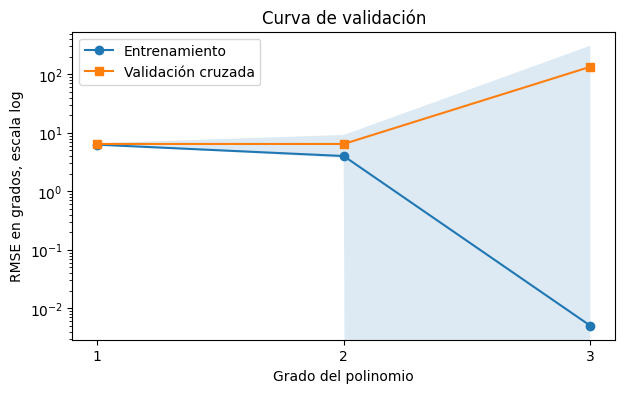

In [49]:
# Pipeline de regresión polinomial para la curva de validación
pipeline_curva = Pipeline([
    ("preprocesamiento", ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler()),
                          ("polynomial", PolynomialFeatures(include_bias=False))]), num_cols),
        ("cat", transformador_cat, cat_cols)])),
    ("modelo", LinearRegression())])


# Grados del polinomio a evaluar
grados = [1, 2, 3]
# Calcula el RMSE de entrenamiento y de validación cruzada para cada grado
train_scores, val_scores = validation_curve(
    pipeline_curva, X_train, y_train,
    param_name="preprocesamiento__num__polynomial__degree", param_range=grados,
    cv=kfold, scoring="neg_root_mean_squared_error", n_jobs=-1)

# Los scores vienen negativos por lo que se convierten a RMSE positivo (media por grado)
train_rmse = -train_scores.mean(axis=1)
val_rmse = -val_scores.mean(axis=1)

# Grafica ambas curvas en escala logarítmica
plt.figure(figsize=(7, 4))
plt.plot(grados, train_rmse, "o-", label="Entrenamiento")
plt.plot(grados, val_rmse, "s-", label="Validación cruzada")
plt.fill_between(grados, val_rmse - (-val_scores).std(axis=1), val_rmse + (-val_scores).std(axis=1), alpha=0.15)
plt.yscale("log")
plt.xticks(grados)
plt.xlabel("Grado del polinomio")
plt.ylabel("RMSE en grados, escala log")
plt.title("Curva de validación")
plt.legend()
plt.show()

La curva de entrenamiento baja siempre, pero la de validación deja de mejorar en el grado 2 y empeora en el grado 3. Ahí la brecha entre ambas crece, lo que evidencia el sobreajuste. El modelo de grado 2 es el más complejo que todavía generaliza.

## 5. Regresión regularizada: Ridge y Lasso

Ridge con penalización L2 y Lasso con penalización L1 reducen el tamaño de los coeficientes para controlar la complejidad. Buscamos el parámetro de penalización alpha y el escalador con validación cruzada.

In [50]:
# Pipeline de Ridge con el preprocesador ya definido
pipeline_ridge = Pipeline([("preprocesamiento", preprocesador), ("modelo", Ridge())])
# Grid: intensidad de la penalización L2 (alpha) y estrategia de escalamiento
param_grid_ridge = {"modelo__alpha": [0.01, 0.1, 1, 10, 100, 1000],
                    "preprocesamiento__num__scaler": [StandardScaler(), MinMaxScaler(), RobustScaler()]}
# Busca el mejor alpha y escalador por validación cruzada
grid_ridge = GridSearchCV(pipeline_ridge, param_grid_ridge, cv=kfold,
                          scoring="neg_root_mean_squared_error", n_jobs=-1)
grid_ridge.fit(X_train, y_train)
# Guarda el mejor estimador y lo evalúa en el conjunto de prueba
mejor_ridge = grid_ridge.best_estimator_
pred = mejor_ridge.predict(X_test)
print("Ridge, mejor configuración:", grid_ridge.best_params_)
print(f"Ridge. RMSE_cv: {-grid_ridge.best_score_:.3f}")
print(f"Ridge. RMSE_test: {np.sqrt(mean_squared_error(y_test, pred)):.3f}  MAE: {mean_absolute_error(y_test, pred):.3f}  R2: {r2_score(y_test, pred):.3f}")

Ridge, mejor configuración: {'modelo__alpha': 1, 'preprocesamiento__num__scaler': MinMaxScaler()}
Ridge. RMSE_cv: 6.440
Ridge. RMSE_test: 6.263  MAE: 4.865  R2: 0.520


In [51]:
# Pipeline de Lasso (con más iteraciones para asegurar la convergencia)
pipeline_lasso = Pipeline([("preprocesamiento", preprocesador), ("modelo", Lasso(max_iter=20000))])
# Grid: intensidad de la penalización L1 (alpha) y estrategia de escalamiento
param_grid_lasso = {"modelo__alpha": [0.001, 0.01, 0.03, 0.1, 0.3, 1],
                    "preprocesamiento__num__scaler": [StandardScaler(), MinMaxScaler(), RobustScaler()]}
# Busca el mejor alpha y escalador por validación cruzada
grid_lasso = GridSearchCV(pipeline_lasso, param_grid_lasso, cv=kfold,
                          scoring="neg_root_mean_squared_error", n_jobs=-1)
grid_lasso.fit(X_train, y_train)
# Guarda el mejor estimador y lo evalúa en el conjunto de prueba
mejor_lasso = grid_lasso.best_estimator_
pred = mejor_lasso.predict(X_test)
print("Lasso, mejor configuración:", grid_lasso.best_params_)
print(f"Lasso. RMSE_cv: {-grid_lasso.best_score_:.3f}")
print(f"Lasso. RMSE_test: {np.sqrt(mean_squared_error(y_test, pred)):.3f}  MAE: {mean_absolute_error(y_test, pred):.3f}  R2: {r2_score(y_test, pred):.3f}")

Lasso, mejor configuración: {'modelo__alpha': 0.03, 'preprocesamiento__num__scaler': StandardScaler()}
Lasso. RMSE_cv: 6.450
Lasso. RMSE_test: 6.272  MAE: 4.877  R2: 0.519


Revisamos los coeficientes del Lasso: cuáles conserva y cuáles lleva a cero. Así hace una selección automática de variables.

In [52]:
# Obtiene los nombres de las variables tras el preprocesamiento
nombres = [n.split("__")[-1] for n in mejor_lasso.named_steps["preprocesamiento"].get_feature_names_out()]
# Arma una tabla con los coeficientes del Lasso por variable
coeficientes = pd.DataFrame({"variable": nombres, "coef_lasso": mejor_lasso.named_steps["modelo"].coef_})
# Ordena por magnitud del coeficiente (las más influyentes primero)
coeficientes = coeficientes.sort_values("coef_lasso", key=abs, ascending=False).reset_index(drop=True)
coeficientes.round(3)

,variable,coef_lasso
0,humedad_desv,2.588
1,humedad_media,-2.104
2,mes_cos,-1.704
3,dia_del_anio,1.621
4,presion_desv,-1.292
5,estacion_anio_primavera,-0.976
6,rafaga_media,-0.846
7,mes_sin,-0.815
8,humedad_min,-0.790
9,viento_desv,0.751


In [53]:
# Lista las variables cuyo coeficiente el Lasso llevó exactamente a cero (selección automática)
en_cero = coeficientes.loc[coeficientes["coef_lasso"] == 0, "variable"].tolist()
print("Variables llevadas a cero por Lasso:", en_cero)

Variables llevadas a cero por Lasso: ['viento_media', 'rafaga_desv', 'estacion_anio_otono', 'estacion_anio_verano']


Ridge y Lasso obtienen prácticamente el mismo desempeño que el modelo lineal: la regularización no mejora mucho porque el modelo lineal no estaba sobreajustado. Lasso deja fuera algunas variables sin perder desempeño, por ejemplo la desviación de la ráfaga y la velocidad media del viento, lo que da un modelo más simple e interpretable. Las variables más influyentes son ahora la variabilidad de la humedad y la estacionalidad, no el viento que el Lab 1 había destacado.

## 6. Regresión polinomial regularizada

Combinamos la expansión polinomial con Ridge y con Lasso. La búsqueda explora el grado y el alpha. Aquí es donde la regularización debería controlar el sobreajuste del polinomio.

In [54]:
# Pipeline que combina la expansión polinomial con Ridge (penalización L2)
pipeline_poly_ridge = Pipeline([
  ("preprocesamiento", ColumnTransformer([
      ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
          ("scaler", StandardScaler()),
          ("polynomial", PolynomialFeatures(include_bias=False))]), num_cols),
      ("cat", transformador_cat, cat_cols)])),
      ("modelo", Ridge())])

# Grilla conjunta: grado del polinomio, alpha y estrategia de escalamiento
param_grid_pr = {"preprocesamiento__num__polynomial__degree": [1, 2, 3],
                 "modelo__alpha": [1, 10, 100, 1000],
                 "preprocesamiento__num__scaler": [StandardScaler(), MinMaxScaler(), RobustScaler()]}

# Busca la mejor combinación por validación cruzada
grid_poly_ridge = GridSearchCV(pipeline_poly_ridge, param_grid_pr, cv=kfold,
                               scoring="neg_root_mean_squared_error", n_jobs=-1)

grid_poly_ridge.fit(X_train, y_train)

# Evalúa el mejor modelo en el conjunto de prueba
pred = grid_poly_ridge.best_estimator_.predict(X_test)

print("Polinomial + Ridge:", grid_poly_ridge.best_params_)
print(f"RMSE_cv: {-grid_poly_ridge.best_score_:.3f}  |  RMSE_test: {np.sqrt(mean_squared_error(y_test, pred)):.3f}  R2: {r2_score(y_test, pred):.3f}")

Polinomial + Ridge: {'modelo__alpha': 1, 'preprocesamiento__num__polynomial__degree': 3, 'preprocesamiento__num__scaler': MinMaxScaler()}
RMSE_cv: 4.640  |  RMSE_test: 4.904  R2: 0.706


In [55]:
# Pipeline que combina la expansión polinomial con Lasso (penalización L1)
pipeline_poly_lasso = Pipeline([
    ("preprocesamiento", ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler()),
                          ("polynomial", PolynomialFeatures(include_bias=False))]), num_cols),
        ("cat", transformador_cat, cat_cols)])),
        ("modelo", Lasso(max_iter=20000))])

# Grid conjunto: Grado del polinomio, alpha y estrategia de escalamiento
param_grid_pl = {"preprocesamiento__num__polynomial__degree": [1, 2, 3],
                 "modelo__alpha": [0.05, 0.1, 0.3, 1],
                 "preprocesamiento__num__scaler": [StandardScaler(), MinMaxScaler(), RobustScaler()]}

# Busca la mejor combinación por validación cruzada
grid_poly_lasso = GridSearchCV(pipeline_poly_lasso, param_grid_pl, cv=kfold,
                               scoring="neg_root_mean_squared_error", n_jobs=-1)

grid_poly_lasso.fit(X_train, y_train)

# Evalúa el mejor modelo en el conjunto de prueba
pred = grid_poly_lasso.best_estimator_.predict(X_test)

print("Polinomial + Lasso:", grid_poly_lasso.best_params_)
print(f"RMSE_cv: {-grid_poly_lasso.best_score_:.3f}  |  RMSE_test: {np.sqrt(mean_squared_error(y_test, pred)):.3f}  R2: {r2_score(y_test, pred):.3f}")

Polinomial + Lasso: {'modelo__alpha': 0.1, 'preprocesamiento__num__polynomial__degree': 2, 'preprocesamiento__num__scaler': StandardScaler()}
RMSE_cv: 4.783  |  RMSE_test: 4.970  R2: 0.698


El polinomio con regularización sí controla el sobreajuste, incluso en grado 3: Ridge encontró que RMSE_cv=4.640 es mejor que grado 2 RMSE_cv=4.783 y muchísimo mejor que grado 3 sin regularizar RMSE_cv=48.132. Esto confirma que la penalización permite aprovechar la mayor flexibilidad del polinomio sin que el modelo se dispare por el número de término

## 7. Comparación y selección del mejor modelo

Reunimos los modelos con su RMSE de validación cruzada, con media y desviación, y su desempeño en prueba. Elegimos considerando el promedio y la estabilidad.

In [56]:
# Función auxiliar para obtener la desviación estándar del mejor resultado de una búsqueda
def std_cv(grid):
    return grid.cv_results_["std_test_score"][grid.best_index_]

# Reúne todos los modelos con su estimador, RMSE de validación cruzada y desviación
modelos = {
    "Lineal Lab 1":      (modelo_lineal, -scores.mean(), scores.std()),
    "Polinomial":          (grid_poly.best_estimator_, -grid_poly.best_score_, std_cv(grid_poly)),
    "Ridge":               (mejor_ridge, -grid_ridge.best_score_, std_cv(grid_ridge)),
    "Lasso":               (mejor_lasso, -grid_lasso.best_score_, std_cv(grid_lasso)),
    "Polinomial + Ridge":  (grid_poly_ridge.best_estimator_, -grid_poly_ridge.best_score_, std_cv(grid_poly_ridge)),
    "Polinomial + Lasso":  (grid_poly_lasso.best_estimator_, -grid_poly_lasso.best_score_, std_cv(grid_poly_lasso)),
}

# Calcula las métricas de cada modelo sobre el conjunto de prueba
filas = []
for nombre, (est, rmse_cv, s) in modelos.items():
    pred = est.predict(X_test)
    filas.append({"Modelo": nombre, "RMSE_cv": rmse_cv, "std_cv": s,
                  "RMSE_test": np.sqrt(mean_squared_error(y_test, pred)),
                  "MAE_test": mean_absolute_error(y_test, pred),
                  "R2_test": r2_score(y_test, pred)})
# Ordena por RMSE de validación cruzada (de mejor a peor)
tabla = pd.DataFrame(filas).sort_values("RMSE_cv").reset_index(drop=True)
tabla.round(3)

,Modelo,RMSE_cv,std_cv,RMSE_test,MAE_test,R2_test
0,Polinomial + Ridge,4.640,0.282,4.904,3.617,0.706
1,Polinomial + Lasso,4.783,0.217,4.970,3.629,0.698
2,Ridge,6.440,0.244,6.263,4.865,0.520
3,Lasso,6.450,0.220,6.272,4.877,0.519
4,Polinomial,6.462,2.756,5.680,4.021,0.605
5,Lineal Lab 1,6.463,0.211,6.257,4.860,0.521


In [57]:
# Toma el primer modelo de la tabla
grids_finales = {
    "Polinomial":          grid_poly,
    "Ridge":               grid_ridge,
    "Lasso":               grid_lasso,
    "Polinomial + Ridge":  grid_poly_ridge,
    "Polinomial + Lasso":  grid_poly_lasso,
}

mejor_nombre = tabla.iloc[0]["Modelo"]
modelo_final = modelos[mejor_nombre][0]
print("Modelo seleccionado:", mejor_nombre)
# Muestra los mejores hiperparámetros encontrados por la búsqueda del modelo final
print("Mejores hiperparámetros:", grids_finales[mejor_nombre].best_params_)

Modelo seleccionado: Polinomial + Ridge
Mejores hiperparámetros: {'modelo__alpha': 1, 'preprocesamiento__num__polynomial__degree': 3, 'preprocesamiento__num__scaler': MinMaxScaler()}


El polinomio de grado 3 con Ridge obtiene el mejor RMSE de validación cruzada 4.640 y también el mejor en prueba (4.904, R²=0.706), con una desviación estándar razonable de 0.282. Es el modelo más complejo de todos los evaluados, pero la regularización L2 mantiene el error de validación controlado, así que lo seleccionamos como modelo final.

## 8. Intervalos de confianza con bootstrap

Estimamos la incertidumbre del RMSE del modelo final con bootstrapping sobre el conjunto de prueba: 1000 remuestreos con reemplazo, y tomamos los percentiles 2.5 y 97.5 para el intervalo de confianza al 95%.

RMSE medio bootstrap: 4.897
Intervalo de confianza 95%: [4.434, 5.470]


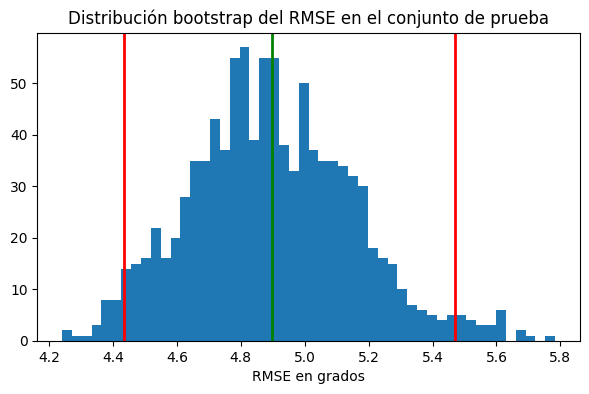

In [58]:
# Predice con el modelo final y pasa las etiquetas reales de prueba a un arreglo
y_pred = modelo_final.predict(X_test)
y_test_arr = y_test.to_numpy()
n = len(y_test_arr)

# Remuestrea los índices de prueba con reemplazo y calcula el RMSE de cada muestra
rmse_boot = []
for i in range(1000):
    idx = resample(np.arange(n), replace=True, n_samples=n, random_state=i)
    rmse_boot.append(np.sqrt(mean_squared_error(y_test_arr[idx], y_pred[idx])))

# Percentiles 2.5 y 97.5 del RMSE: intervalo de confianza al 95%
lower, upper = np.percentile(rmse_boot, [2.5, 97.5])
print(f"RMSE medio bootstrap: {np.mean(rmse_boot):.3f}")
print(f"Intervalo de confianza 95%: [{lower:.3f}, {upper:.3f}]")

# Grafica la distribución del RMSE del bootstrap con el intervalo y la media
plt.figure(figsize=(7, 4))
plt.hist(rmse_boot, bins=50)
plt.axvline(lower, color="red", linewidth=2)
plt.axvline(upper, color="red", linewidth=2)
plt.axvline(np.mean(rmse_boot), color="green", linewidth=2)
plt.xlabel("RMSE en grados")
plt.title("Distribución bootstrap del RMSE en el conjunto de prueba")
plt.show()

El intervalo es estrecho, con poco más de 1 grado de ancho, lo que indica que el desempeño del modelo es estable y sus predicciones son confiables dentro de ese margen. La desviación estándar de la temperatura en prueba es cercana a 9 grados, así que un error típico de unos 5 grados representa una reducción real frente a predecir siempre el promedio.

## 9. Análisis de resultados

Análisis cuantitativo

- Cuál modelo obtuvo el mejor desempeño en prueba. El polinomial con Ridge de grado 3, con un RMSE cercano a 4.90 y R²=0.706, frente a unos 6.3 grados del modelo lineal.
- Coincide el mejor en prueba con el mejor en validación cruzada. El polinomial con Ridge de grado 3 es el mejor en ambos. Los demás modelos quedan muy cerca entre sí y sus diferencias caben dentro de la desviación de la validación cruzada.
- El mejor promedio es necesariamente el más adecuado. No solo se mira el promedio. El polinomial con Ridge combina buen promedio y desviación razonable. El polinomial con Lasso combina buen promedio y baja desviación, por eso es preferible.
- Curvas de validación. El error de entrenamiento baja siempre y el de validación mejora hasta el grado 2 y empeora en el grado 3. El sobreajuste se evidencia cuando la brecha entre ambas curvas crece.
- Cómo afecta la regularización a los coeficientes. Ridge reduce los coeficientes y Lasso lleva varios exactamente a cero. Ambos reducen su magnitud y hacen el modelo más estable frente al lineal sin regularizar.
- Los intervalos de confianza sugieren estabilidad. Sí, el intervalo del RMSE es estrecho, cercano a 1 grado, lo que indica un desempeño estable y predicciones confiables dentro de ese margen.

Análisis cualitativo

- Variables seleccionadas por Lasso. Conserva como más influyentes la variabilidad de la humedad, la humedad media, la estacionalidad del mes y del día del año y la variabilidad de la presión. Lleva a cero la velocidad media del viento y la desviación de la ráfaga, entre otras.
- Interpretación de los coeficientes. En el modelo lineal regularizado cada coeficiente es el cambio esperado en grados de la temperatura de mañana ante un aumento de una desviación estándar de la variable. Dominan la variabilidad de la humedad y la estacionalidad, no los promedios.
- Preciso frente a interpretable. El polinomial con Ridge es el más preciso, pero al no eliminar ningún coeficiente regularización L2 es difícil de interpretar término a término. El lineal con Lasso sigue siendo la opción más interpretable, con pocas variables activas. Recomendamos el polinomial con Ridge para predecir y el lineal con Lasso para explicar.
- Decisiones para AlpesPlanck. Las variables clave para anticipar la temperatura son la variabilidad intradía de la humedad y la estacionalidad. Además conviene auditar la calidad de los datos de viento, porque contenían valores corruptos que en el Lab 1 hacían parecer al viento la variable más importante.
- Mayor precisión implica más valor. No siempre. El error típico de unos 5 grados sigue siendo alto para alertas críticas como incendios, y el modelo más preciso es más difícil de mantener y explicar.
- Un modelo más complejo genera más valor. Depende del uso. Para operar conviene el polinomial regularizado reportando su intervalo de error, y para comunicar los factores conviene el lineal más simple.

Reflexión conceptual

- Complejidad, generalización y estabilidad. Subir la complejidad sin regularizar mejora el ajuste en entrenamiento pero empeora la generalización y aumenta la varianza. La regularización recupera generalización y estabiliza los coeficientes.
- Fuentes de sesgo. Sesgo de medición, porque los datos de viento corruptos alteraban qué variables parecían importantes. Sesgo temporal, porque usamos validación cruzada aleatoria sobre una serie diaria, lo que puede ser optimista frente a predecir el futuro. Y una sola estación y rango de años, que limita la generalización.
- Más datos cambiarían la estabilidad. Sí. Con más datos el error de validación bajaría y el polinomio de grado alto dejaría de tener más columnas que filas, reduciendo su varianza. Con la muestra actual la regularización suple esa falta de datos.

## 10. Uso de herramientas de IA generativa

### Declaración del uso:
Se utilizó Claude Code de Anthropic como apoyo conceptual y de planificación: repasar el enunciado y las prácticas P5 y P6, proponer la estructura del notebook, sugerir esqueletos de código para los pipelines y la búsqueda de hiperparámetros, y ayudar con la redacción. No se usaron otras herramientas de IA generativa.

### Prompts principales:
Primero, planear el Laboratorio 2 siguiendo el estilo de las prácticas del curso. Segundo, diagnosticar por qué la validación cruzada daba errores enormes sobre los datos del Lab 1, con lo que detectamos los valores de viento fuera de rango. Tercero, proponer las grillas de hiperparámetros para Ridge, Lasso y el polinomio.

### Análisis crítico:
Lo útil fue la estructura por actividades y la detección de los valores de viento corruptos. Lo que corregimos: una primera propuesta sugería no tocar esos valores y compensarlos con el escalador, pero al elevarlos al cuadrado seguían dominando, así que decidimos acotarlos por rango físico. También ajustamos las grillas y verificamos cada resultado ejecutando el código nosotros. Los conceptos del curso que usamos para evaluar las respuestas fueron el balance entre sesgo y varianza, la validación cruzada y la regularización.

### Aportes propios:
Las decisiones fueron del equipo y están justificadas con lo visto en el curso: cómo tratar los datos de viento, qué variables usar, qué modelo elegir y cómo interpretarlo. Todo el código fue comprendido y adaptado, y las cifras y conclusiones se obtuvieron ejecutando el notebook.